# Nimbus-5 ESMR Swath to EASE-Grid Resampling

This notebook demonstrates how to:
1. **Load Nimbus-5 ESMR L1 swath data** in NetCDF format (co-located with ERA5 atmospheric reanalysis).
2. **Swath quality filtering**: drop noisy edge scan positions 0–3 and 74–77 (keeping mid-swath 4–73).
3. **Resample swath observations onto polar EASE grids** (25 km resolution) using `pyresample` for both the Arctic (`ease_nh`) and Antarctic (`ease_sh`).
4. **Apply standard land masks** (`lmask_nh_ease_250.nc`, `lmask_sh_ease_250.nc`).
5. **Visualize resampled brightness temperatures ($T_B$)** and save quicklook figures.

> **Path Independence:** Paths dynamically resolve whether running from repository root or directly inside `provided/resampling_example/`.

In [1]:
import os
import glob
from netCDF4 import Dataset
import numpy as np
import matplotlib.pyplot as plt
import pyresample as pr

%matplotlib inline

# Auto-detect project paths
current_dir = os.path.abspath(os.getcwd())
if os.path.basename(current_dir) == "resampling_example":
    base_dir = os.path.abspath(os.path.join(current_dir, "../.."))
    resample_dir = current_dir
else:
    base_dir = current_dir
    resample_dir = os.path.join(base_dir, "provided", "resampling_example")

data_dir = os.path.join(base_dir, "ESMR_colocated_filtered")
cfg_file = os.path.join(resample_dir, "areas_ease.cfg")
lmask_nh_file = os.path.join(resample_dir, "lmask_nh_ease_250.nc")
lmask_sh_file = os.path.join(resample_dir, "lmask_sh_ease_250.nc")
output_dir = os.path.join(base_dir, "output", "resampling")
os.makedirs(output_dir, exist_ok=True)

print(f"Project base:     {base_dir}")
print(f"ESMR data:        {data_dir} (found: {os.path.exists(data_dir)})")
print(f"EASE grid config: {cfg_file} (found: {os.path.exists(cfg_file)})")
print(f"Land mask NH:     {lmask_nh_file} (found: {os.path.exists(lmask_nh_file)})")
print(f"Land mask SH:     {lmask_sh_file} (found: {os.path.exists(lmask_sh_file)})")
print(f"Output directory: {output_dir}")

Project base:     /Users/joannesruckdeschel/Developer/30350-remote-sensing
ESMR data:        /Users/joannesruckdeschel/Developer/30350-remote-sensing/ESMR_colocated_filtered (found: True)
EASE grid config: /Users/joannesruckdeschel/Developer/30350-remote-sensing/provided/resampling_example/areas_ease.cfg (found: True)
Land mask NH:     /Users/joannesruckdeschel/Developer/30350-remote-sensing/provided/resampling_example/lmask_nh_ease_250.nc (found: True)
Land mask SH:     /Users/joannesruckdeschel/Developer/30350-remote-sensing/provided/resampling_example/lmask_sh_ease_250.nc (found: True)
Output directory: /Users/joannesruckdeschel/Developer/30350-remote-sensing/output/resampling


## Swath Aggregation, Gridding & Masking Function

The function `resample_day` (aliased as `iskoncentration` for compatibility):
- Reads all orbit files for a given date (e.g. `1973m0201`).
- Extracts mid-swath scan positions 4–73.
- Defines polar swath geometries for Northern and Southern Hemispheres.
- Maps swath data onto 25 km EASE grids via KD-tree nearest-neighbor resampling (`radius_of_influence=50000` m).
- Overlays the 250 m / 25 km land-sea binary masks.
- Produces publication-ready quicklook plots and saves them to `output/resampling/`.

In [2]:
def resample_day(aar="1973", maaned="02", dag="01", radius_of_influence=50000, save_plots=True):
    """
    Loads all ESMR orbits for a given day, resamples brightness temperature to Northern
    and Southern Hemisphere EASE grids, applies land masking, and plots/saves the results.
    """
    pattern = f"Nimbus5-ESMR_{aar}m{maaned}{dag}*.nc"
    search_path = os.path.join(data_dir, pattern)
    filename_list = sorted(glob.glob(search_path))

    if not filename_list:
        raise FileNotFoundError(f"No ESMR files found matching: {search_path}")

    print(f"Found {len(filename_list)} orbit files for date {aar}-{maaned}-{dag}:")
    for fn in filename_list[:3]:
        print(f"  - {os.path.basename(fn)}")
    if len(filename_list) > 3:
        print(f"  ... and {len(filename_list) - 3} more files.")

    lats_list, lons_list = [], []
    sst_list, t2m_list = [], []
    tcw_list, tcwv_list = [], []
    u10_list, v10_list = [], []
    siconc_list, Tb_list = [], []

    for filename in filename_list:
        with Dataset(filename, "r") as ds:
            lats_list.append(ds.variables["Latitude"][:])
            lons_list.append(ds.variables["Longitude"][:])
            sst_list.append(ds.variables["sst"][:])
            t2m_list.append(ds.variables["t2m"][:])
            tcw_list.append(ds.variables["tcw"][:])
            tcwv_list.append(ds.variables["tcwv"][:])
            u10_list.append(ds.variables["u10"][:])
            v10_list.append(ds.variables["v10"][:])
            siconc_list.append(ds.variables["siconc"][:])
            Tb_list.append(ds.variables["Brightness_temperature"][:])

    lat = np.concatenate(lats_list)
    lon = np.concatenate(lons_list)
    sst = np.concatenate(sst_list)
    siconc = np.concatenate(siconc_list)
    Tb = np.concatenate(Tb_list)

    # Mid-swath selection: discard edge beams 0..3 and 74..77 (keep 4..73)
    mid_swath = slice(4, 74)
    lat = lat[:, mid_swath]
    lon = lon[:, mid_swath]
    sst = sst[:, mid_swath]
    siconc = siconc[:, mid_swath]
    Tb = Tb[:, mid_swath]

    # Geographic and validity masks
    valid = (~np.isnan(lat)) & (~np.isnan(lon)) & (~np.isnan(Tb))
    arctic_mask = valid & (lat > 32) & (lat <= 90)
    antarctic_mask = valid & (lat < -48) & (lat >= -90)

    print(f"Arctic valid observations:    {np.sum(arctic_mask):,}")
    print(f"Antarctic valid observations: {np.sum(antarctic_mask):,}")

    # Wrap longitudes to [-180, 180]
    lon_n, lat_n = pr.utils.check_and_wrap(lon[arctic_mask], lat[arctic_mask])
    lon_s, lat_s = pr.utils.check_and_wrap(lon[antarctic_mask], lat[antarctic_mask])

    # Define swath geometries
    arctic_def = pr.geometry.SwathDefinition(lons=lon_n, lats=lat_n)
    antarctic_def = pr.geometry.SwathDefinition(lons=lon_s, lats=lat_s)

    # Load EASE Grid definitions from areas_ease.cfg
    area_def_north_ease = pr.parse_area_file(cfg_file, "ease_nh")[0]
    area_def_south_ease = pr.parse_area_file(cfg_file, "ease_sh")[0]

    # Resample nearest-neighbor using KDTree
    print("Resampling Arctic to EASE-NH grid (25 km)...")
    n_Tb = pr.kd_tree.resample_nearest(
        arctic_def, Tb[arctic_mask], area_def_north_ease,
        radius_of_influence=radius_of_influence, fill_value=np.nan
    )

    print("Resampling Antarctic to EASE-SH grid (25 km)...")
    s_Tb = pr.kd_tree.resample_nearest(
        antarctic_def, Tb[antarctic_mask], area_def_south_ease,
        radius_of_influence=radius_of_influence, fill_value=np.nan
    )

    # Load land masks (0 = ocean/ice, 1 = land)
    with Dataset(lmask_nh_file, "r") as dn:
        land_mask_arctic = dn.variables["lmask"][:] > 0.5
    with Dataset(lmask_sh_file, "r") as ds:
        land_mask_antarctic = ds.variables["lmask"][:] > 0.5

    # Mask land pixels
    n_Tb_ocean = np.where(land_mask_arctic, np.nan, n_Tb)
    s_Tb_ocean = np.where(land_mask_antarctic, np.nan, s_Tb)

    # Plotting
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    im0 = axes[0].imshow(n_Tb_ocean, vmin=100, vmax=270, cmap="plasma", origin="upper")
    axes[0].set_title(f"Arctic EASE-NH $T_B$ [K]\n({aar}-{maaned}-{dag}, land masked)", fontsize=12)
    axes[0].set_xticks([])
    axes[0].set_yticks([])
    fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label="$T_B$ [K]")

    im1 = axes[1].imshow(s_Tb_ocean, vmin=100, vmax=270, cmap="plasma", origin="upper")
    axes[1].set_title(f"Antarctic EASE-SH $T_B$ [K]\n({aar}-{maaned}-{dag}, land masked)", fontsize=12)
    axes[1].set_xticks([])
    axes[1].set_yticks([])
    fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04, label="$T_B$ [K]")

    plt.tight_layout()

    if save_plots:
        plot_filename = f"N5_ESMR_Tb_{aar}{maaned}{dag}_EASE_resampled_quicklook.png"
        plot_path = os.path.join(output_dir, plot_filename)
        plt.savefig(plot_path, dpi=150, bbox_inches="tight")
        print(f"Quicklook saved to: {plot_path}")

    plt.show()

    return {
        "n_Tb": n_Tb,
        "s_Tb": s_Tb,
        "n_Tb_ocean": n_Tb_ocean,
        "s_Tb_ocean": s_Tb_ocean,
        "area_nh": area_def_north_ease,
        "area_sh": area_def_south_ease
    }

# Backward compatibility alias
iskoncentration = resample_day

## Run Resampling for 1973-02-01

Run the complete pipeline on the first day of our NIMBUS-5 ESMR dataset.

Found 12 orbit files for date 1973-02-01:
  - Nimbus5-ESMR_1973m0201t022301_DS32.nc
  - Nimbus5-ESMR_1973m0201t042157_DS32.nc
  - Nimbus5-ESMR_1973m0201t060005_DS32.nc
  ... and 9 more files.


Arctic valid observations:    403,296
Antarctic valid observations: 298,158
Resampling Arctic to EASE-NH grid (25 km)...
Resampling Antarctic to EASE-SH grid (25 km)...


Quicklook saved to: /Users/joannesruckdeschel/Developer/30350-remote-sensing/output/resampling/N5_ESMR_Tb_19730201_EASE_resampled_quicklook.png


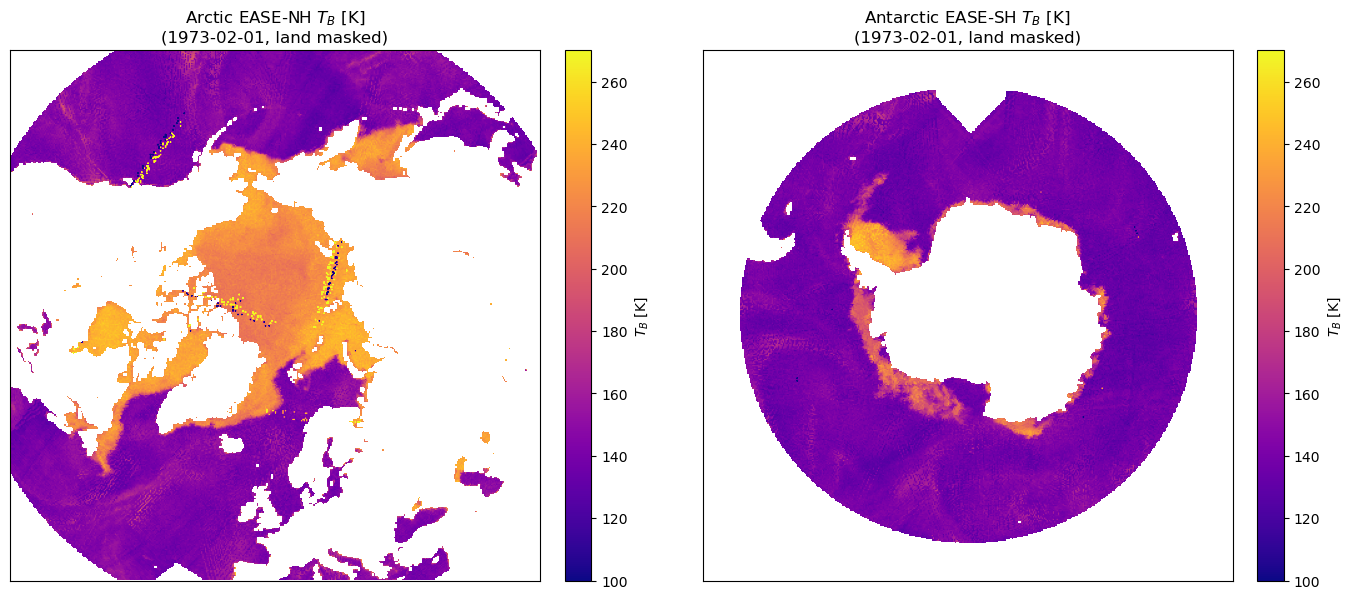

In [3]:
results = resample_day(aar="1973", maaned="02", dag="01")

## Summary Statistics of the Resampled Grids

Examine the resulting gridded brightness temperature distributions across both polar regions.

In [4]:
print("=== Arctic (EASE-NH) ===")
print(f"Grid dimensions:        {results['n_Tb'].shape} (25 km EASE grid)")
print(f"Valid ocean/ice pixels: {np.sum(~np.isnan(results['n_Tb_ocean'])):,}")
print(f"Mean ocean/ice Tb:      {np.nanmean(results['n_Tb_ocean']):.2f} K")
print(f"Std dev ocean/ice Tb:   {np.nanstd(results['n_Tb_ocean']):.2f} K")
print(f"Min / Max ocean/ice Tb: {np.nanmin(results['n_Tb_ocean']):.2f} K / {np.nanmax(results['n_Tb_ocean']):.2f} K")

print("\n=== Antarctic (EASE-SH) ===")
print(f"Grid dimensions:        {results['s_Tb'].shape} (25 km EASE grid)")
print(f"Valid ocean/ice pixels: {np.sum(~np.isnan(results['s_Tb_ocean'])):,}")
print(f"Mean ocean/ice Tb:      {np.nanmean(results['s_Tb_ocean']):.2f} K")
print(f"Std dev ocean/ice Tb:   {np.nanstd(results['s_Tb_ocean']):.2f} K")
print(f"Min / Max ocean/ice Tb: {np.nanmin(results['s_Tb_ocean']):.2f} K / {np.nanmax(results['s_Tb_ocean']):.2f} K")

=== Arctic (EASE-NH) ===
Grid dimensions:        (425, 425) (25 km EASE grid)
Valid ocean/ice pixels: 85,787
Mean ocean/ice Tb:      169.39 K
Std dev ocean/ice Tb:   42.70 K
Min / Max ocean/ice Tb: -186.40 K / 671.10 K

=== Antarctic (EASE-SH) ===
Grid dimensions:        (425, 425) (25 km EASE grid)
Valid ocean/ice pixels: 81,757
Mean ocean/ice Tb:      143.36 K


Std dev ocean/ice Tb:   18.96 K
Min / Max ocean/ice Tb: -76.90 K / 273.40 K
